In [1]:
import os
import kagglehub
from google.colab import drive

#drive.mount('/content/drive')

download_path = kagglehub.dataset_download("divg07/casia-20-image-tampering-detection-dataset")

if not os.path.exists('/content/dataset'):
    os.symlink(download_path, '/content/dataset')

100%|██████████| 2.56G/2.56G [00:28<00:00, 97.0MB/s]

Extracting files...


In [2]:
import io
import os
import glob
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageChops, ImageEnhance

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [3]:
# Update these two paths to match your local CASIA dataset folders
DRIVE_PROJECT_PATH = "/content/drive/MyDrive/IPCV_Forgery_Detection"
os.makedirs(DRIVE_PROJECT_PATH, exist_ok=True)


LOCAL_DATASET_PATH = "/content/dataset/CASIA2"
AUTH_PATH = os.path.join(LOCAL_DATASET_PATH, "Au")
TAMP_PATH = os.path.join(LOCAL_DATASET_PATH, "Tp")

print("Authentic images:", len(os.listdir(AUTH_PATH)))
print("Tampered images:", len(os.listdir(TAMP_PATH)))
print("Outputs will be saved to:", DRIVE_PROJECT_PATH)

IMG_HEIGHT = 128
IMG_WIDTH = 128
IMG_CHANNELS = 3
IMAGE_SIZE = (IMG_WIDTH, IMG_HEIGHT)

BATCH_SIZE = 32
EPOCHS = 30
ELA_QUALITY = 90

Authentic images: 7492
Tampered images: 5125
Outputs will be saved to: /content/drive/MyDrive/IPCV_Forgery_Detection


In [4]:
def convert_to_ela_image(image_path, quality=ELA_QUALITY):
    """Computes Error Level Analysis (ELA) entirely in RAM using BytesIO."""
    try:
        original_image = Image.open(image_path).convert('RGB')

        # Re-compress in memory instead of writing temp_resaved.jpg to disk
        buffer = io.BytesIO()
        original_image.save(buffer, format='JPEG', quality=quality)
        buffer.seek(0)
        resaved_image = Image.open(buffer)

        # Compute absolute pixel-wise difference and rescale brightness
        ela_image = ImageChops.difference(original_image, resaved_image)
        extrema = ela_image.getextrema()
        max_diff = max([ex[1] for ex in extrema]) or 1
        scale = 255.0 / max_diff
        ela_image = ImageEnhance.Brightness(ela_image).enhance(scale)

        return ela_image.resize(IMAGE_SIZE, Image.Resampling.LANCZOS)
    except Exception as e:
        print(f"Skipping corrupted file {image_path}: {e}")
        return None

In [5]:
import gc

start_prep = time.time()

valid_exts = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff')

authentic_images = [
    p for ext in valid_exts
    for p in glob.glob(os.path.join(AUTH_PATH, "**", ext), recursive=True)
]
tampered_images = [
    p for ext in valid_exts
    for p in glob.glob(os.path.join(TAMP_PATH, "**", ext), recursive=True)
    if not p.lower().endswith(('_gt.png', '_gt.bmp'))
]

X, y, original_paths = [], [], []

for label, paths in [(0, authentic_images), (1, tampered_images)]:
    for path in paths:
        ela_img = convert_to_ela_image(path)
        if ela_img is not None:
            # Keep as uint8 (0-255) instead of float32 -> 4x smaller RAM footprint!
            X.append(np.asarray(ela_img, dtype=np.uint8))
            y.append(label)
            original_paths.append(path)

X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int32)
original_paths = np.array(original_paths)

# Stratified 80% Train / 10% Val / 10% Test split
X_train, X_temp, y_train, y_temp, paths_train, paths_temp = train_test_split(
    X, y, original_paths, test_size=0.2, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test, paths_val, paths_test = train_test_split(
    X_temp, y_temp, paths_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Free full-dataset buffers immediately to reclaim CPU RAM
del X, X_temp, y, y_temp, original_paths, paths_temp
gc.collect()

print(f"Preprocessing completed in {time.time() - start_prep:.2f}s")
print(f"X_train RAM usage: {X_train.nbytes / (1024**2):.1f} MB (uint8)")
print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Preprocessing completed in 207.38s
X_train RAM usage: 473.0 MB (uint8)
Train: (10091, 128, 128, 3) | Val: (1261, 128, 128, 3) | Test: (1262, 128, 128, 3)


In [6]:
from tensorflow.keras.layers import Rescaling

def build_lightweight_forgery_cnn(input_shape):
    inputs = Input(shape=input_shape, name="ela_input")

    # Normalize uint8 [0, 255] -> float32 [0.0, 1.0] on the T4 GPU per batch
    x = Rescaling(1.0 / 255.0, name="gpu_rescaling")(inputs)

    # Block 1
    x = Conv2D(32, (3, 3), activation='relu', padding='same', name="conv_block1")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    # Block 2
    x = Conv2D(64, (3, 3), activation='relu', padding='same', name="conv_block2")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    # Block 3 (Target layer for Grad-CAM)
    x = Conv2D(128, (3, 3), activation='relu', padding='same', name="last_conv_layer")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    # Lightweight Head (~110K total params)
    x = GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    outputs = Dense(1, activation='sigmoid', name="prediction")(x)

    return Model(inputs=inputs, outputs=outputs, name="Lightweight_ELA_CNN_v2")

model = build_lightweight_forgery_cnn((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
model.summary()

Model: "Lightweight_ELA_CNN_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ela_input (InputLayer)          │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gpu_rescaling (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block1 (Conv2D)            │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block2 (Conv2D)            │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv_layer (Conv2D)        │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [7]:
import gc
gc.collect()

def make_dataset(images, labels, batch_size=32, shuffle=False):
    """Streams batches from uint8 NumPy arrays without cloning the full array in CPU RAM."""
    def gen():
        indices = np.arange(len(images))
        if shuffle:
            np.random.shuffle(indices)
        for i in indices:
            yield images[i], labels[i]

    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec(shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
val_ds = make_dataset(X_val, y_val, batch_size=BATCH_SIZE, shuffle=False)

# Balanced class weights
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(weights))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

checkpoint = ModelCheckpoint(
    'best_model_v2.keras',
    save_best_only=True,
    monitor='val_loss',
    mode='min',
    verbose=1
)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

start_train = time.time()
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr]
)
print(f"Training completed in {time.time() - start_train:.2f}s")

Epoch 1/30
    316/Unknown 29s 50ms/step - accuracy: 0.8401 - auc: 0.9020 - loss: 0.3745

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.87783, saving model to best_model_v2.keras

Epoch 1: finished saving model to best_model_v2.keras
316/316 ━━━━━━━━━━━━━━━━━━━━ 36s 71ms/step - accuracy: 0.8680 - auc: 0.9239 - loss: 0.3336 - val_accuracy: 0.4060 - val_auc: 0.3523 - val_loss: 0.8778 - learning_rate: 0.0010
Epoch 2/30
314/316 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8751 - auc: 0.9402 - loss: 0.2942
Epoch 2: val_loss improved from 0.87783 to 0.35308, saving model to best_model_v2.keras

Epoch 2: finished saving model to best_model_v2.keras
316/316 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8853 - auc: 0.9477 - loss: 0.2741 - val_accuracy: 0.8462 - val_auc: 0.9611 - val_loss: 0.3531 - learning_rate: 0.0010
Epoch 3/30
315/316 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8914 - auc: 0.9579 - loss: 0.2514
Epoch 3: val_loss improved from 0.35308 to 0.27221, saving model to best_model_v2.keras

Epoch 3: finished saving model to best_model_v2.keras
316/316 ━━━━━━━━━━━━━━

40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step

--- Version 2 Classification Report ---
              precision    recall  f1-score   support

   Authentic     0.9655    0.8972    0.9301       749
    Tampered     0.8640    0.9532    0.9064       513

    accuracy                         0.9200      1262
   macro avg     0.9147    0.9252    0.9182      1262
weighted avg     0.9242    0.9200    0.9205      1262

Test ROC-AUC Score: 0.9753


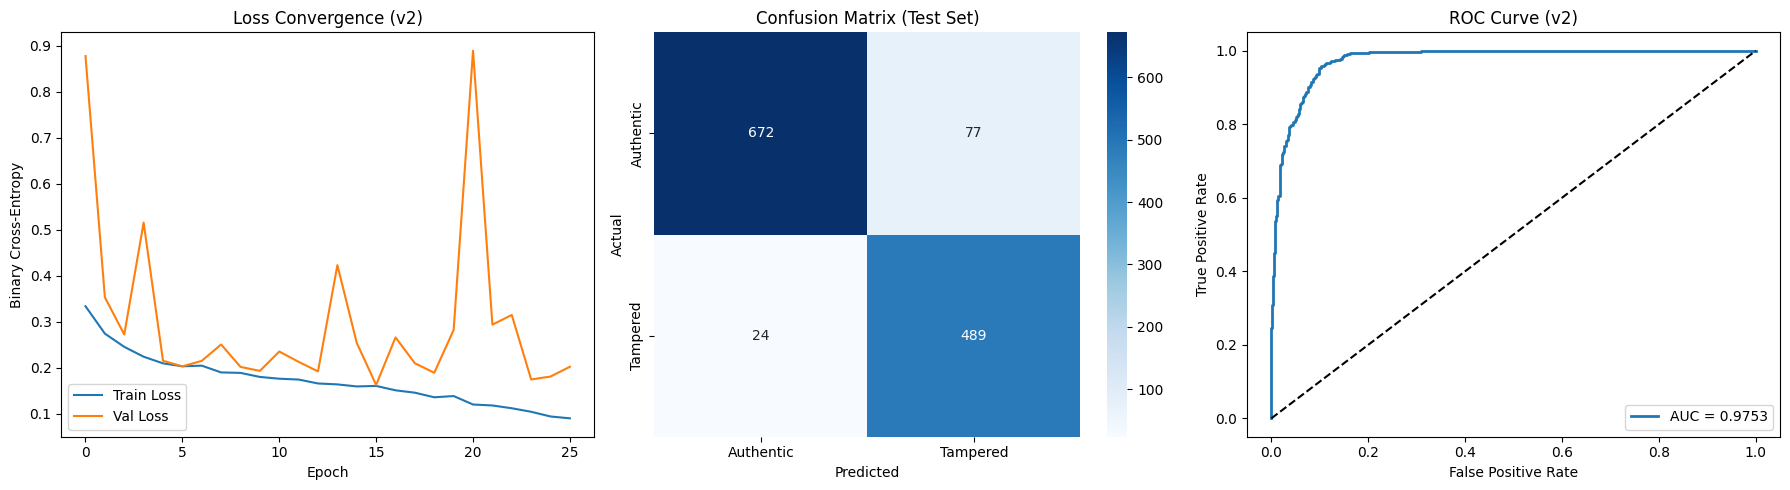

In [8]:
# Load best val_loss checkpoint
model = tf.keras.models.load_model('best_model_v2.keras')

y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

print("\n--- Version 2 Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Authentic', 'Tampered'], digits=4))

roc_auc = roc_auc_score(y_test, y_pred_prob)
print(f"Test ROC-AUC Score: {roc_auc:.4f}")

# Plot Training Curves, Confusion Matrix & ROC Curve side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss Curve
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss Convergence (v2)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy')
axes[0].legend()

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
    xticklabels=['Authentic', 'Tampered'],
    yticklabels=['Authentic', 'Tampered']
)
axes[1].set_title('Confusion Matrix (Test Set)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# 3. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
axes[2].plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}', linewidth=2)
axes[2].plot([0, 1], [0, 1], 'k--')
axes[2].set_title('ROC Curve (v2)')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

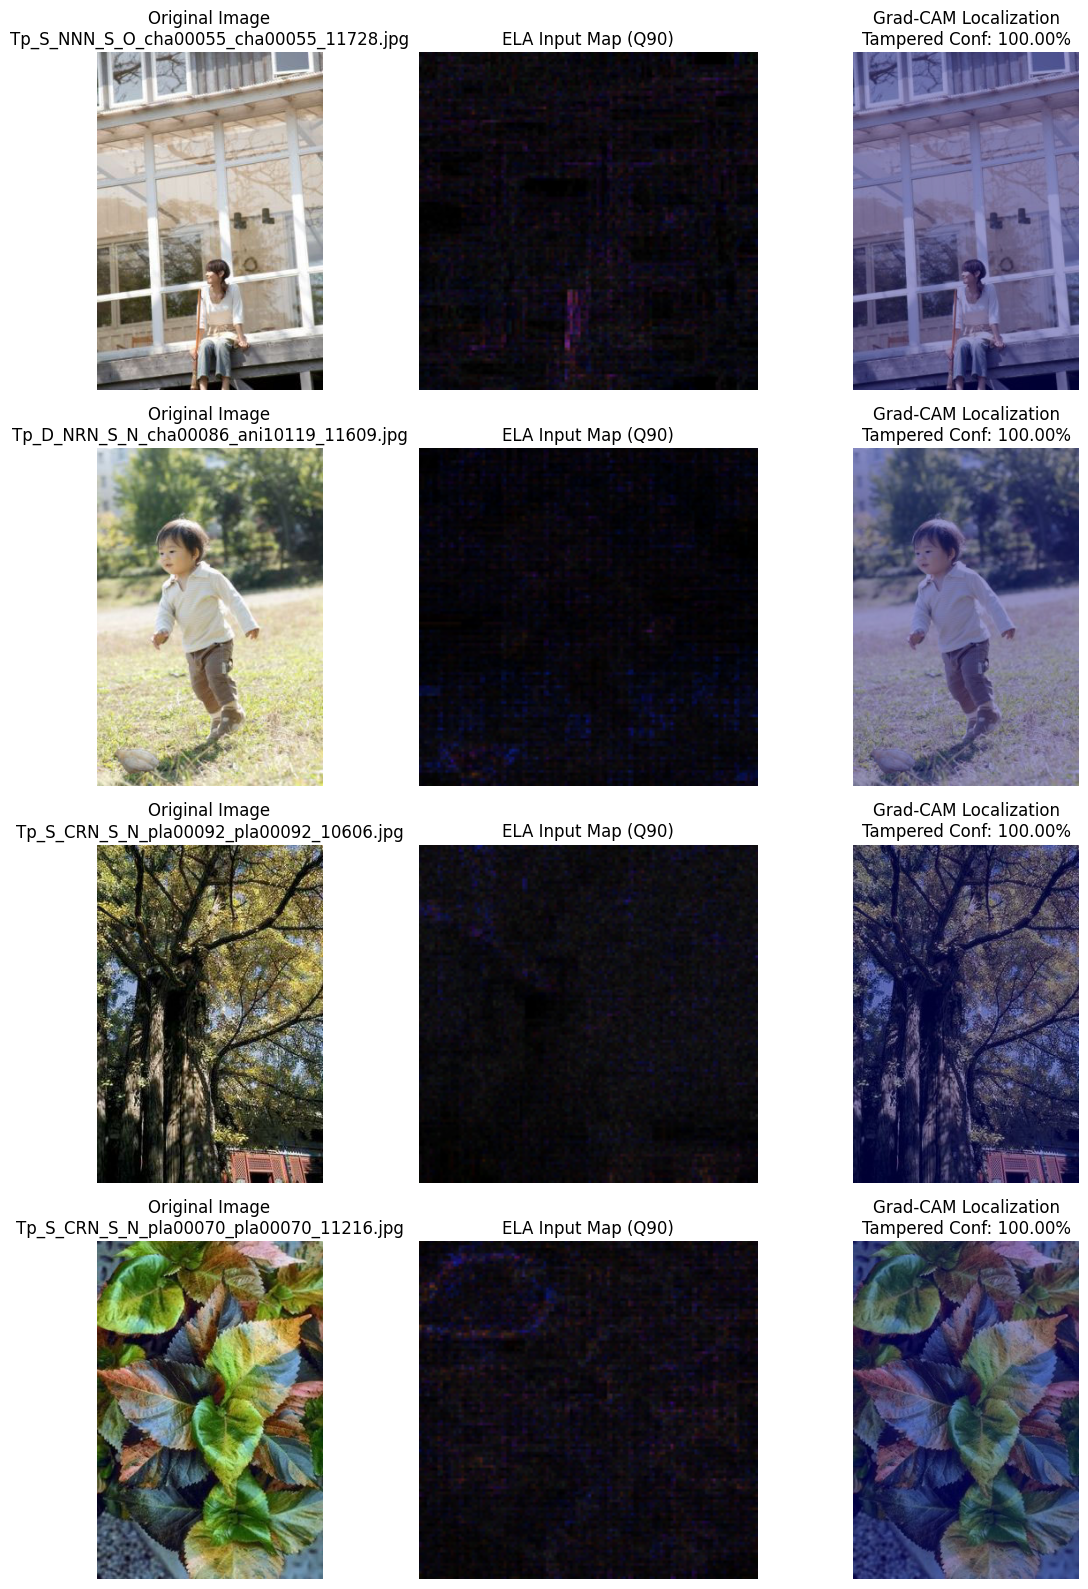

In [9]:
def generate_gradcam(model, img_tensor, layer_name="last_conv_layer"):
    """Generates a normalized Grad-CAM heatmap for a single preprocessed ELA tensor."""
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(tf.expand_dims(img_tensor, axis=0))
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(predictions[0][0])

# Pick 4 correctly detected Tampered test images with highest confidence
tampered_indices = np.where((y_test == 1) & (y_pred == 1))[0]
top_indices = tampered_indices[np.argsort(y_pred_prob[tampered_indices])[-4:]]

fig, axes = plt.subplots(len(top_indices), 3, figsize=(12, 4 * len(top_indices)))

for row, idx in enumerate(top_indices):
    orig_bgr = cv2.imread(paths_test[idx])
    orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = orig_rgb.shape

    heatmap, prob = generate_gradcam(model, X_test[idx])
    heatmap_resized = cv2.resize(heatmap, (w, h))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(orig_rgb, 0.6, heatmap_color, 0.4, 0)

    axes[row, 0].imshow(orig_rgb)
    axes[row, 0].set_title(f"Original Image\n{os.path.basename(paths_test[idx])}")
    axes[row, 0].axis('off')

    axes[row, 1].imshow(X_test[idx])
    axes[row, 1].set_title("ELA Input Map (Q90)")
    axes[row, 1].axis('off')

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(f"Grad-CAM Localization\nTampered Conf: {prob:.2%}")
    axes[row, 2].axis('off')

plt.tight_layout()
plt.show()